<a href="https://colab.research.google.com/github/inesnair/birdsfinder/blob/main/02_entrainement_antilles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!git clone https://github.com/inesnair/birdsfinder.git
%cd birdsfinder
!pip -q install -r requirements-train.txt

Mounted at /content/drive
Cloning into 'birdsfinder'...
remote: Enumerating objects: 152, done.
remote: Counting objects: 100% (152/152), done.
remote: Compressing objects: 100% (129/129), done.
remote: Total 152 (delta 32), reused 57 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (152/152), 2.16 MiB | 10.37 MiB/s, done.
Resolving deltas: 100% (32/32), done.
/content/birdsfinder


Lire les images directement sur le Drive est très lent : chaque photo passe par le réseau, à chaque époque. Je copie une seule fois mes 948 photos nettoyées sur le disque local de Colab.

In [ ]:
DRIVE = "/content/drive/MyDrive/birdsfinder"
SOURCE = f"{DRIVE}/data_antilles_10/images_propres"
DATA = "/content/data_antilles_10"

!rm -rf "$DATA" && cp -r "$SOURCE" "$DATA"

from pathlib import Path
for d in sorted(Path(DATA).iterdir()):
    print(f"{len(list(d.glob('*.jpg'))):3d}  {d.name}")

 92  Bubulcus_ibis
 99  Coereba_flaveola
 89  Eulampis_jugularis
 98  Loxigilla_noctis
100  Melanospiza_bicolor
 99  Mimus_gilvus
 91  Orthorhyncus_cristatus
 98  Quiscalus_lugubris
 87  Tyrannus_dominicensis
 95  Zenaida_aurita


1er entrainement

In [ ]:
!python -m src.train_cnn --model resnet18 --epochs 12 --data "$DATA" --out /content/runs_antilles10

Appareil : cuda | modèle : resnet18
948 images, 10 espèces
train=663 | val=142 | test=143
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 190MB/s]
époque  1/12 | train loss 2.244 acc 0.178 | val loss 1.968 acc 0.289 top3 0.662 | 7s
époque  2/12 | train loss 1.753 acc 0.446 | val loss 1.680 acc 0.451 top3 0.768 | 7s
époque  3/12 | train loss 1.457 acc 0.563 | val loss 1.526 acc 0.493 top3 0.796 | 6s
>>> Phase 2 : on dégèle tout le réseau (fine-tuning)
époque  4/12 | train loss 1.121 acc 0.656 | val loss 0.918 acc 0.676 top3 0.894 | 8s
époque  5/12 | train loss 0.529 acc 0.873 | val loss 0.851 acc 0.704 top3 0.901 | 6s
époque  6/12 | train loss 0.345 acc 0.929 | val loss 0.824 acc 0.711 top3 0.915 | 7s
époque  7/12 | train loss 0.212 acc 0.964 | val loss 0.804 acc 0.725 top3 0.923 | 6s
époque  8/12 | train loss 0.142 acc 0.986 | val loss 0.795 acc 0.732 top3 0.923 | 6s
époq

résultat

{
  "model": "resnet18",
  "best_epoch": 8,
  "val_acc": 0.7323943661971831,
  "test_loss": 0.7438516250023475,
  "test_acc": 0.7272727272727273,
  "test_top3": 0.9090909090909091,
  "macro_f1": 0.7249998682532416,
  "n_classes": 10
}


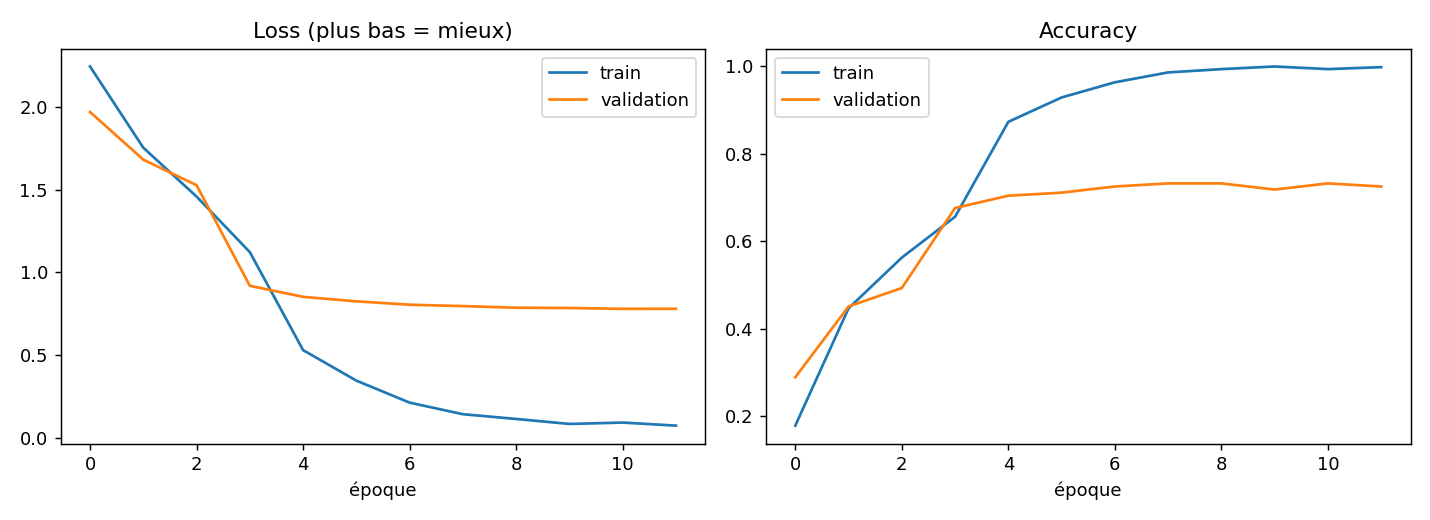

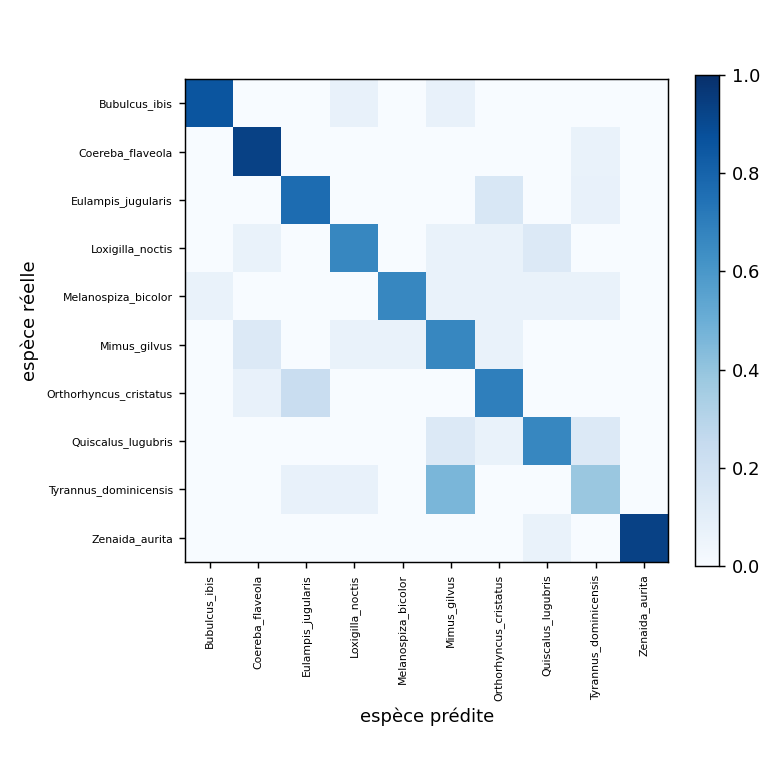

In [ ]:
from IPython.display import Image as Img, display
import json
R = "/content/runs_antilles10/resnet18"
print(json.dumps(json.load(open(f"{R}/metrics.json")), indent=2))
display(Img(f"{R}/curves.png"))
display(Img(f"{R}/confusion_matrix.png"))

!mkdir -p "$DRIVE/runs_antilles10" && cp -r /content/runs_antilles10/resnet18 "$DRIVE/runs_antilles10/"   # sauvegarde Drive

Je regarde le score de chaque espèce pour savoir lesquelles posent problème, et si mes groupes « pièges » se confondent vraiment

,precision,recall,f1-score,support
Tyrannus_dominicensis,0.50,0.38,0.43,13.0
Mimus_gilvus,0.48,0.67,0.56,15.0
Orthorhyncus_cristatus,0.60,0.69,0.64,13.0
Quiscalus_lugubris,0.71,0.67,0.69,15.0
Loxigilla_noctis,0.77,0.67,0.71,15.0
Eulampis_jugularis,0.71,0.77,0.74,13.0
Melanospiza_bicolor,0.91,0.67,0.77,15.0
Coereba_flaveola,0.78,0.93,0.85,15.0
Bubulcus_ibis,0.92,0.86,0.89,14.0
Zenaida_aurita,1.00,0.93,0.97,15.0


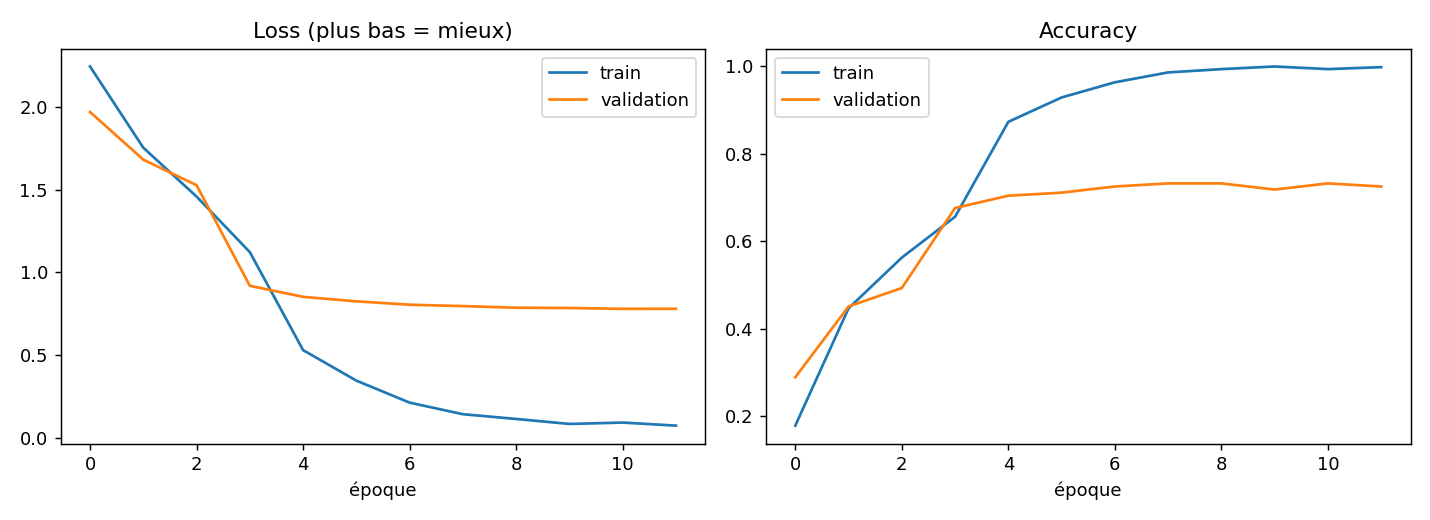

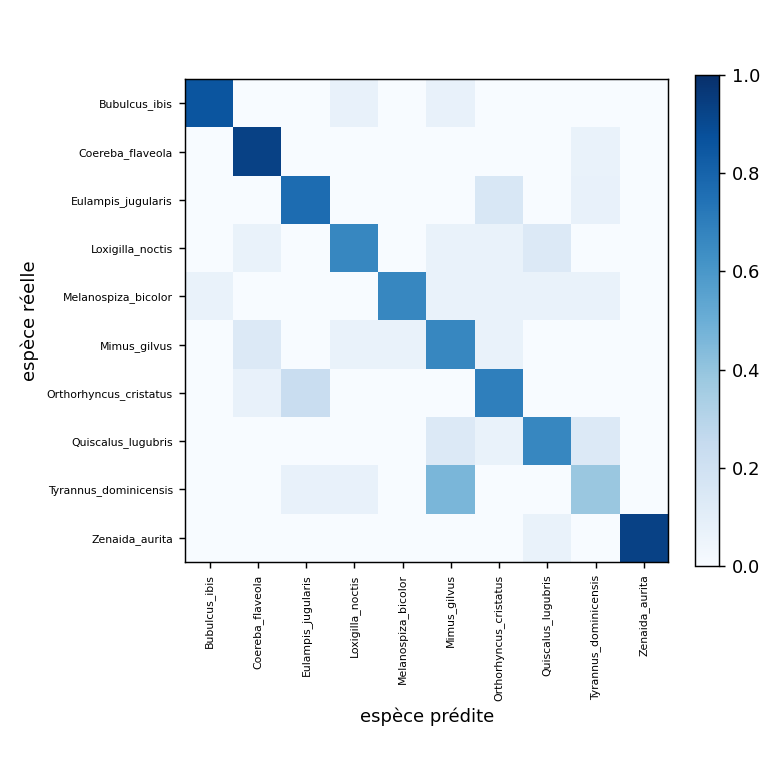

In [ ]:
import json
import pandas as pd
from IPython.display import Image as Img, display

R = "/content/runs_antilles10/resnet18"

rep = json.load(open(f"{R}/classification_report.json"))
scores = pd.DataFrame({k: v for k, v in rep.items() if k not in ("accuracy", "macro avg", "weighted avg")}).T
scores = scores[["precision", "recall", "f1-score", "support"]].sort_values("f1-score")
display(scores.round(2))
display(Img(f"{R}/curves.png"))
display(Img(f"{R}/confusion_matrix.png"))

courbes : L’écart croissant entre train et validation à partir de l’époque 5 montre du surapprentissage : le modèle mémorise les photos d’entraînement. Les garde-fous ont limité les dégâts : je garde le modèle de la meilleure époque en validation, et l’early stopping arrête l’entraînement

matrice : Les faciles le sont vraiment
Tourterelle à queue carrée (Zenaida) et Sucrier (Coereba) : diagonale très foncée, plus de 90 %.
Héron garde-bœufs : environ 85 %.
🩶 Le piège des gris a parfaitement marché, c’est ton point le plus fort
Tyran gris (Tyrannus) : seulement environ 30 % de bonnes réponses, et environ 45 % des tyrans sont pris pour des Moqueurs des savanes (Mimus). C’est la plus grosse confusion de toute la matrice.
Ta lecture de biologiste vaut de l’or ici : les deux espèces sont grises dessus, claires dessous, de taille proche. Ce qui les distingue (le masque sombre et le gros bec du tyran, la longue queue à bords blancs du moqueur) se perd sur une photo prise de loin et réduite à 224 pixels.
💚 Le piège des colibris aussi

Les confusions vont dans les deux sens : environ 20 % des Campyloptères huppés sont pris pour des Colibris madère, et environ 15 % dans l’autre sens.

⚫ Les noirs : moins piégeux que prévu
Le Pèrenoir est parfois pris pour un Quiscale (environ 15 %).
Le Cici verdinère est surtout dispersé : ses erreurs vont vers plusieurs espèces différentes, et non vers les deux autres noirs. C’est un petit oiseau, souvent photographié de loin, donc une photo floue ou lointaine plutôt qu’une confusion « logique ».
🤍 Le piège blanc : impossible à tester

Il n’y a aucune aigrette dans tes 10 espèces, donc le héron n’a rien avec quoi se confondre. À dire honnêtement si on te pose la question, ou à corriger si tu ajoutes une aigrette plus tard.

\

Je compare 3 architectures dans les mêmes conditions (mêmes données, mêmes réglages, 12 époques), chacune sur 3 découpages différents (graines 42, 7 et 2026). Chaque entraînement est tracé dans MLflow. Je mesure aussi la durée de chacun.

In [ ]:
import time

MODELES = ["resnet18", "efficientnet_b0", "convnext_tiny"]
GRAINES = [42, 7, 2026]
RUNS = "/content/runs_antilles10_compare"
durees = {}

for seed in GRAINES:
    for m in MODELES:
        print(f"\n{'=' * 60}\n▶ {m} | graine {seed}\n{'=' * 60}")
        t0 = time.time()
        !python -m src.train_cnn --model {m} --epochs 12 --seed {seed} --data "$DATA" --out {RUNS}/seed{seed} --mlflow
        durees[(m, seed)] = time.time() - t0


▶ resnet18 | graine 42
Appareil : cuda | modèle : resnet18
948 images, 10 espèces
train=663 | val=142 | test=143
2026/11/20 21:11:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/20 21:11:01 INFO mlflow.store.db.utils: Updating database tables
2026/11/20 21:11:03 INFO mlflow.tracking.fluent: Experiment with name 'birdsfinder-cnn' does not exist. Creating a new experiment.
époque  1/12 | train loss 2.244 acc 0.178 | val loss 1.968 acc 0.289 top3 0.662 | 7s
époque  2/12 | train loss 1.753 acc 0.446 | val loss 1.680 acc 0.451 top3 0.768 | 5s
époque  3/12 | train loss 1.457 acc 0.563 | val loss 1.526 acc 0.493 top3 0.796 | 7s
>>> Phase 2 : on dégèle tout le réseau (fine-tuning)
époque  4/12 | train loss 1.121 acc 0.655 | val loss 0.917 acc 0.669 top3 0.901 | 6s
époque  5/12 | train loss 0.529 acc 0.873 | val loss 0.852 acc 0.704 top3 0.908 | 7s
époque  6/12 | train loss 0.345 acc 0.929 | val loss 0.823 acc 0.711 top3 0.908 | 6s
époque  7/12 | train loss 0.

Je rassemble les résultats des 9 entraînements et je calcule, pour chaque modèle, la moyenne et l’écart-type sur les 3 graines, ainsi que la taille du fichier et la durée d’entraînement

In [ ]:
import json, os
import pandas as pd

lignes = []
for seed in GRAINES:
    for m in MODELES:
        d = f"{RUNS}/seed{seed}/{m}"
        met = json.load(open(f"{d}/metrics.json"))
        lignes.append({
            "modèle": m, "graine": seed,
            "accuracy": met["test_acc"], "top3": met["test_top3"], "macro_f1": met["macro_f1"],
            "meilleure époque": met["best_epoch"],
            "taille (Mo)": os.path.getsize(f"{d}/best.pt") / 1e6,
            "durée (s)": durees.get((m, seed), float("nan")),
        })

detail = pd.DataFrame(lignes)
display(detail.round(3))

resume = detail.groupby("modèle").agg(
    accuracy_moy=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    top3_moy=("top3", "mean"),
    macro_f1_moy=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
    taille_Mo=("taille (Mo)", "mean"), duree_s=("durée (s)", "mean"),
).sort_values("macro_f1_moy", ascending=False)
display(resume.round(3))

resume.to_csv(f"{RUNS}/comparaison_modeles.csv")

,modèle,graine,accuracy,top3,macro_f1,meilleure époque,taille (Mo),durée (s)
0,resnet18,42,0.720,0.916,0.717,9,44.799,95.336
1,efficientnet_b0,42,0.769,0.930,0.762,12,16.361,94.651
2,convnext_tiny,42,0.881,0.993,0.877,8,111.366,203.401
3,resnet18,7,0.825,0.951,0.820,10,44.799,96.695
4,efficientnet_b0,7,0.790,0.958,0.790,10,16.361,99.844
5,convnext_tiny,7,0.916,0.986,0.916,5,111.366,146.122
6,resnet18,2026,0.755,0.937,0.756,8,44.799,94.139
7,efficientnet_b0,2026,0.741,0.958,0.736,10,16.361,101.320
8,convnext_tiny,2026,0.874,0.965,0.871,5,111.366,145.471


,accuracy_moy,accuracy_std,top3_moy,macro_f1_moy,macro_f1_std,taille_Mo,duree_s
modèle,,,,,,,
convnext_tiny,0.890,0.022,0.981,0.888,0.025,111.366,164.998
resnet18,0.767,0.053,0.935,0.764,0.052,44.799,95.390
efficientnet_b0,0.767,0.025,0.949,0.763,0.027,16.361,98.605


In [ ]:
!mkdir -p "$DRIVE/runs_antilles10_compare"
!cp -r {RUNS}/* "$DRIVE/runs_antilles10_compare/"
!cp -r /content/birdsfinder/mlruns "$DRIVE/runs_antilles10_compare/"
print("Sauvegardé sur le Drive ✅")

Sauvegardé sur le Drive ✅


Je compare le score de chaque espèce entre les 3 modèles, en moyenne sur les 3 graines, pour voir si ConvNeXt progresse sur les espèces difficiles.

modèle,resnet18,efficientnet_b0,convnext_tiny
espèce,,,
Orthorhyncus_cristatus,0.75,0.71,0.81
Quiscalus_lugubris,0.65,0.75,0.82
Tyrannus_dominicensis,0.61,0.54,0.83
Loxigilla_noctis,0.72,0.66,0.86
Mimus_gilvus,0.67,0.72,0.87
Eulampis_jugularis,0.79,0.84,0.89
Melanospiza_bicolor,0.75,0.78,0.89
Coereba_flaveola,0.85,0.81,0.96
Zenaida_aurita,0.91,0.90,0.97


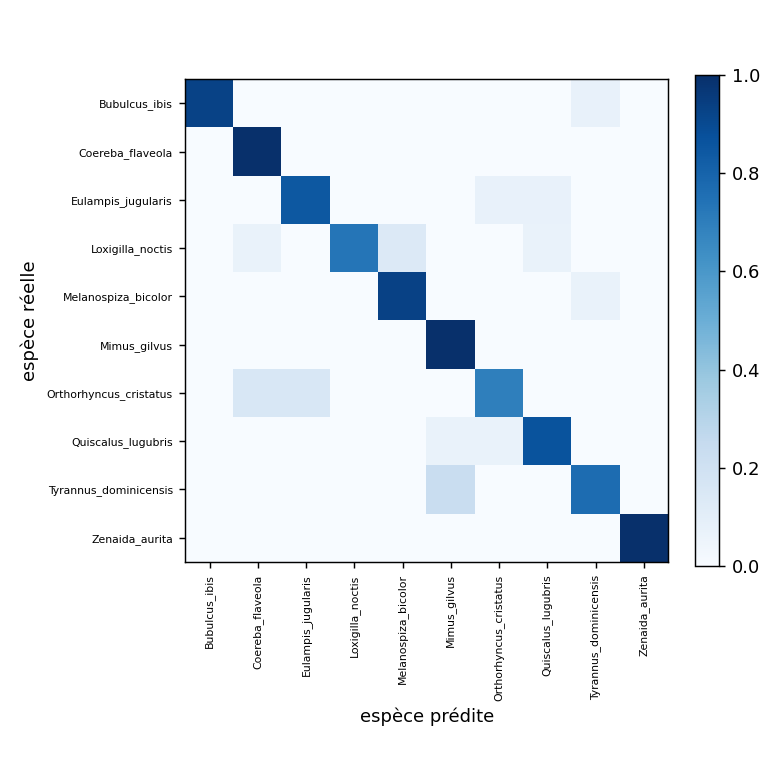

In [ ]:
par_espece = []
for seed in GRAINES:
    for m in MODELES:
        rep = json.load(open(f"{RUNS}/seed{seed}/{m}/classification_report.json"))
        for esp, v in rep.items():
            if esp not in ("accuracy", "macro avg", "weighted avg"):
                par_espece.append({"modèle": m, "espèce": esp, "f1": v["f1-score"]})

tableau = (pd.DataFrame(par_espece)
           .pivot_table(index="espèce", columns="modèle", values="f1", aggfunc="mean")
           [MODELES].sort_values("convnext_tiny"))
display(tableau.round(2))
display(Img(f"{RUNS}/seed42/convnext_tiny/confusion_matrix.png"))

ConvNeXt-Tiny ne progresse pas uniformément : ses gains les plus forts portent sur les espèces que j’avais choisies comme pièges (Tyran gris +22 points, Moqueur des savanes +20). Le modèle plus récent distingue mieux les détails fins entre espèces proches. Les colibris restent la principale difficulté. Une piste d’amélioration serait d’ajouter des photos pour ces espèce

In [ ]:
FINAL = f"{DRIVE}/modele_final_antilles"
!mkdir -p "$FINAL"

# 1) le modèle retenu
!cp {RUNS}/seed42/convnext_tiny/best.pt "$FINAL/best.pt"

# 2) la table des noms : dossier d'espèce -> nom français / scientifique
!python -m src.make_classes_json --counts "$DRIVE/data_antilles_10/species_counts.csv" --images "$DATA" --out "$FINAL/classes.json"

!ls -lh "$FINAL"
!cat "$FINAL/classes.json"

10 espèces écrites dans /content/drive/MyDrive/birdsfinder/modele_final_antilles/classes.json
total 107M
-rw------- 1 root root 107M Nov 20 21:34 best.pt
-rw------- 1 root root 1009 Nov 20 21:34 classes.json
{
  "Bubulcus_ibis": {
    "fr": "Héron garde-boeufs, Pique bœufs",
    "sci": "Bubulcus ibis"
  },
  "Coereba_flaveola": {
    "fr": "Sucrier à poitrine jaune, Sucrier à ventre jaune, Sucrier falle jaune, Sucrier cage",
    "sci": "Coereba flaveola"
  },
  "Eulampis_jugularis": {
    "fr": "Colibri madère",
    "sci": "Eulampis jugularis"
  },
  "Loxigilla_noctis": {
    "fr": "Pèrenoir rougegorge",
    "sci": "Loxigilla noctis"
  },
  "Melanospiza_bicolor": {
    "fr": "Cici verdinère",
    "sci": "Melanospiza bicolor"
  },
  "Mimus_gilvus": {
    "fr": "Moqueur des savanes",
    "sci": "Mimus gilvus"
  },
  "Orthorhyncus_cristatus": {
    "fr": "Campyloptère huppé",
    "sci": "Orthorhyncus cristatus"
  },
  "Quiscalus_lugubris": {
    "fr": "Quiscale merle",
    "sci": "Quiscal

In [ ]:
!python -m src.export_onnx --ckpt {RUNS}/seed42/convnext_tiny/best.pt --data "$DATA" --classes-json "$FINAL/classes.json" --region antilles --out export/antilles

1/3 Export ONNX…
/content/birdsfinder/src/export_onnx.py:42: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, str(path), **kwargs)
2/3 Compression int8…
3/3 Contrôle sur 143 photos de test…
  100/143 images évaluées

Résultats sur le test :
  pytorch    accuracy 0.881 | top-3 0.993 | macro-F1 0.877
  onnx_fp32  accuracy 0.881 | top-3 0.993 | macro-F1 0.877 | accord avec PyTorch 1.000
  onnx_int8  accuracy 0.888 | top-3 0.986 | macro-F1 0.884 | accord avec PyTorch 0.993

Fichier retenu : model_int8.onnx (33.8 Mo), perte d'accuracy int8 = -0.7 point(s)
Fiche écrite : export/antilles/model_card.json  ->  étape suivante : python -m

In [ ]:
import os
from google.colab import userdata
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

!python -m src.publish_model --export export/antilles --repo inesnair/birdsfinder-models

manifest.json: 100% 9.98k/9.98k [00:00<00:00, 5.13MB/s]
Envoi de model_int8.onnx (33.8 Mo) vers inesnair/birdsfinder-models/antilles/2026-11-20-convnext_tiny/model.onnx…
Processing Files (0 / 0)      : |          |  0.00B /  0.00B            
New Data Upload               : |          |  0.00B /  0.00B            

  .../antilles/model_int8.onnx:   2% 534k/33.8M [00:00<?, ?B/s]

Processing Files (0 / 1)      :   2% 534k/33.8M [00:01<01:19, 418kB/s, 52.0kB/s  ]
New Data Upload               :   2% 534k/33.8M [00:01<01:19, 418kB/s, 52.0kB/s  ]

  .../antilles/model_int8.onnx:   2% 534k/33.8M [00:00<?, ?B/s]

  .../antilles/model_int8.onnx:   2% 534k/33.8M [00:00<?, ?B/s]

  .../antilles/model_int8.onnx:   2% 534k/33.8M [00:00<?, ?B/s]

Processing Files (0 / 1)      :   3% 1.07M/33.8M [00:01<00:46, 700kB/s,  101kB/s  ]
New Data Upload               :   3% 1.07M/33.8M [00:01<00:46, 700kB/s,  101kB/s  ]

Processing Files (0 / 1)      :   8% 2.67M/33.8M [00:01<00:14, 2.22MB/s,  254kB/s  ]
Ne

In [ ]:
!mkdir -p "$DRIVE/runs_antilles10_compare"
!cp -r {RUNS}/* "$DRIVE/runs_antilles10_compare/"
!cp -r /content/birdsfinder/mlruns "$DRIVE/runs_antilles10_compare/"
print("Sauvegardé sur le Drive ✅")

Sauvegardé sur le Drive ✅
